# Phase 2 — Technical Application: Baseline Implementation (Option A)

Student: Dushara, KIC-BSCCSAI-251P-052
Paper: TD-MPC2: Scalable, Robust World Models for Continuous Control — Hansen, Su, Wang, ICLR 2024
(arXiv:2310.16828, `github.com/nicklashansen/tdmpc2`, commit `e9f59321933cbc8e11a002b842adc7d4ffae8ff1`)
Coursework brief: `cw_descriptor_bscai_ds.pdf`, Section 2 ("Phase 2: Technical Application — 25 Marks")

This notebook is the Phase 2 submission itself. I've tried to make it readable on its own, so a marker
doesn't need the chat history or any outside explanation to follow what was run, what the numbers mean,
and where they fall short. Each code cell has a short note before it saying what it does, and a short
note after its output saying what it shows (and what it doesn't).

## What the brief actually asks for

> *"Option A (Baseline Implementation): Locate the dataset used in the paper (or a highly similar
> open-source dataset). Using Python and libraries such as Scikit-Learn or PyTorch, build and train a
> simple baseline model (e.g., Logistic Regression, Random Forest). Compare your baseline metrics against
> the authors' advanced methodology."*

TD-MPC2 is a reinforcement learning paper, so this doesn't translate literally. There's no fixed labelled
dataset to fit a Logistic Regression or Random Forest on — instead an agent learns by repeatedly
interacting with a simulated environment. The brief's suggested baselines are written with supervised
learning in mind, and the reinforcement-learning equivalent of "a simple baseline model" is a standard
model-free algorithm. I used SAC (Soft Actor-Critic) for that. It's also the same category of method the
TD-MPC2 paper itself compares against in its own Figure 5/6, so this isn't an arbitrary substitution —
it's a baseline the authors themselves treat as meaningful.

## What's in this notebook

1. A quick primer on the RL concepts needed to follow the rest of it.
2. A clear statement of what came from the authors' code/checkpoints, what came from a third-party
   library (`stable-baselines3`), and what's my own code.
3. The experimental setup — hardware, software, tasks, and what's held constant between TD-MPC2 and SAC
   (and what isn't).
4. What training actually happened and what evidence survives for it, including what wasn't saved,
   stated plainly rather than glossed over.
5. The pretrained-checkpoint evaluation ("the authors' advanced methodology").
6. The SAC baseline ("the simple baseline model").
7. A comparison table and chart, with a discussion of what it does and doesn't actually show.
8. Limitations, how to reproduce this, a conclusion, and a file map.

## Completed vs. not verified

Completed: pretrained TD-MPC2 checkpoint evaluation on 3 tasks using the official `evaluate.py`; a SAC
baseline trained from scratch on the same 3 tasks using `stable-baselines3`; a direct comparison with the
fairness caveats stated explicitly rather than hidden.

Also included, though not required by Phase 2: a Gaussian observation-noise robustness test, and a
training-steps/model-size sweep that trained TD-MPC2 itself from scratch five times on `cheetah-run`. The
brief puts stress-testing in Phase 3, where it only needs a stated hypothesis — these were run anyway
since the sweep ran unattended, and they give stronger evidence than required for that later section.
They're marked **[Phase 3 bonus material]** wherever they come up below.

Not available: per-episode scores for either the pretrained evaluation or the SAC runs (only the
aggregate mean/std survive — see Section 6); a saved SAC model file (none was ever written to disk); a raw
terminal transcript of the SAC training run (it printed live to the terminal and wasn't redirected to a
log file). These gaps are stated in Section 6 rather than filled in with invented numbers.

## 1. Basic reinforcement learning concepts

This section defines the terms used through the rest of the notebook, using the three tasks evaluated
here as running examples: `cheetah-run`, `walker-walk`, `hopper-hop` — DeepMind Control Suite locomotion
tasks of increasing difficulty (a 2D cheetah body, a bipedal walker, and a one-legged hopper), each
rewarded for moving forward at some target speed or height.

- **Reinforcement learning (RL):** training a decision-making system (an *agent*) by letting it act in an
  environment and learn from the numerical feedback (*reward*) it gets back, rather than from a fixed set
  of labelled examples like in supervised learning.
- **Agent:** the learner/decision-maker — here, either TD-MPC2's planner or the SAC policy network.
- **Environment:** the simulated physical system the agent interacts with, e.g. the `cheetah-run` physics
  simulation (MuJoCo, via `dm_control`).
- **Observation:** the numbers the agent receives describing the current state — for these tasks, a flat
  vector of joint angles, joint velocities, and body position/orientation values (17 numbers for
  `cheetah-run`, confirmed directly in Section 4).
- **Action:** the numbers the agent outputs to control the environment — joint torques, one per actuated
  joint (6 for `cheetah-run`).
- **Reward:** a single number the environment returns after each action, showing how good that step was.
  For these tasks, higher reward roughly means moving correctly at the target speed/height.
- **Episode:** one complete attempt, from a reset to a fixed time limit (500 agent decision steps for all
  three tasks here) or early termination.
- **Episode return:** the sum of rewards over one episode. This is the main number reported throughout —
  "mean return 851.9" means the agent collected, on average, a total of 851.9 reward across an episode.
- **Training:** updating the agent's parameters (network weights) from experience so future actions get
  higher reward.
- **Evaluation:** running the already-trained, fixed agent and measuring its return without further
  learning. Every "mean return" number in this notebook comes from evaluation-mode runs.
- **Baseline:** a simpler, standard method used as a point of comparison for a more sophisticated one —
  SAC is the baseline here, TD-MPC2 is the method under study.
- **Pretrained checkpoint:** a saved copy of a model's already-learned parameters. The TD-MPC2 numbers
  here come from the authors' own released checkpoints, not from training TD-MPC2 myself (except in the
  Phase 3 bonus sweep, Section 5.2).
- **Random seed:** a fixed starting number for the random number generator used to set up an environment
  or initialise a network. Fixing a seed makes one run reproducible, but a single seed says nothing about
  how much results would vary with a different one — see the limitations in Section 9.

## 2. What I actually implemented and used

It's worth separating four different sources of code and results here, for an honest account of what's
mine and what isn't:

| Source | What it is | Used for |
|---|---|---|
| Authors' released checkpoints | Pretrained TD-MPC2 weights (`cheetah-run-1.pt`, `walker-walk-1.pt`, `hopper-hop-1.pt`), downloaded from `huggingface.co/nicklashansen/tdmpc2` | Section 6 (the pretrained evaluation) — "the authors' advanced methodology" |
| Authors' repository code, unmodified | `evaluate.py`, `train.py`, and everything they call into (`common/`, `envs/`, `tdmpc2.py`, `trainer/`) | Running evaluation and, in the bonus sweep, training — always through the official command-line interface, never edited |
| Third-party library | `stable_baselines3.SAC`, the actual baseline algorithm | Section 7 — I didn't write SAC from scratch; using a standard, well-tested implementation is normal practice for "a simple baseline model," not a shortcut |
| My own code | `DMControlGymEnv` (the environment wrapper), `sac_baseline.py`, `stress_test_noise.py`, and this notebook's orchestration/comparison/plotting cells | Gluing the above together and producing the comparison |

Why I needed a wrapper class: the authors' own environment wrapper
(`tdmpc2/envs/dmcontrol.py::DMControlWrapper`) returns the old 4-tuple Gym API (`obs, reward, done, info`)
with raw PyTorch tensors. `stable-baselines3` needs the newer Gymnasium 5-tuple API
(`obs, reward, terminated, truncated, info`) and NumPy arrays. `DMControlGymEnv` (Section 7) wraps the same
underlying `dm_control.suite` environment, matching TD-MPC2's own settings exactly (action repeat, episode
length, action rescaling), so neither method gets an easier or harder version of the task.

Evaluating a checkpoint is not the same as reproducing training. Running the pretrained checkpoint
through `evaluate.py` tells me the released artefact behaves as claimed on this machine. It does zero
gradient updates — no training happens in that step. It isn't a reproduction of the multi-million-step
training process that produced the checkpoint in the first place, and this notebook doesn't claim
otherwise.

`RUN_LIVE` and `RUN_LIVE_SAC`: both evaluation sections below have a boolean flag (`RUN_LIVE` for the
TD-MPC2 pretrained evaluation, `RUN_LIVE_SAC` for the SAC baseline), both defaulting to `False`. When
`False`, the cell just reads a previously-saved CSV and does nothing beyond `pandas.read_csv` — the
table/plot is historical data, not a fresh run, regardless of what execution-count number Jupyter shows
next to the cell (that number only means "this cell was run," not "this cell retrained a model"). Setting
either flag to `True` makes that section genuinely retrain or re-evaluate from scratch, through the same
functions either way. I left retraining off by default because it's expensive (SAC takes about 20 minutes
per task; the TD-MPC2 evaluation needs a CUDA GPU and the downloaded checkpoints) — "Run All" on this
notebook as shipped finishes in well under a minute.

## 3. Experimental setup

### 3.1 Hardware and software

- Hardware: Intel i5-12450HX, 27GB RAM, NVIDIA RTX 2050 laptop GPU (4GB VRAM), Ubuntu 24.04. The TD-MPC2
  codebase hardcodes `cuda:0` with no CPU fallback (`train.py` and `evaluate.py` both
  `assert torch.cuda.is_available()`), so a working CUDA GPU is required for every TD-MPC2 step here. SAC
  can run on CPU or GPU; I ran it on the same GPU (`device='auto'`).
- Software (installed versions, checked directly on 2026-10-14): `torch==2.7.1+cu126`, `numpy==1.26.4`,
  `scipy==1.13.1`, `gymnasium==0.29.1`, `dm_control==1.0.16`, `mujoco==3.1.2`, `stable_baselines3==2.9.0`,
  `omegaconf==2.3.0`, `hydra-core==1.3.2`. `numpy` is deliberately pinned to the 1.x line — `dm_control`
  needs it, and two unrelated installs in this project (`pandas`, then `matplotlib`) each silently pulled
  in `numpy 2.x` as a transitive dependency, which breaks `dm_control`'s `env.reset()`. Full incident
  record in `TDMPC2_SETUP_GUIDE.md`.
- Repository revision: `github.com/nicklashansen/tdmpc2`, commit
  `e9f59321933cbc8e11a002b842adc7d4ffae8ff1`, checked with `git rev-parse HEAD` in the cloned repo.

### 3.2 Tasks, observation/action spaces

| Task | Domain/task (dm_control) | Observation dim | Action dim |
|---|---|---|---|
| `cheetah-run` | `cheetah`/`run` | 17 | 6 |
| `walker-walk` | `walker`/`walk` | 24 | 6 |
| `hopper-hop` | `hopper`/`hop` | 15 | 4 |

(All three rows checked directly against `dm_control.suite`'s own `observation_spec()`/`action_spec()` for
this task/domain pair, not copied from the paper; `cheetah-run`'s is also confirmed live in Section 4's
demo cell.)

### 3.3 Three different kinds of "step"

Worth being precise about this once, since it's a common source of confusion:

- Simulator step: one physics integration step inside MuJoCo. Not directly visible in this notebook's
  numbers.
- Agent decision step: one call to the agent's policy/planner, after which the chosen action is held
  fixed for `action_repeat=2` simulator steps before the agent is asked again. This is what "episode
  length 500" refers to throughout — 500 agent decisions per episode, each holding its action for 2
  simulator steps (1000 simulator steps total per episode).
- Gradient update / training step: one update to the agent's network weights from a batch of past
  experience. For TD-MPC2, "steps" in `steps=50000` etc. means agent decision steps collected in the
  replay buffer, with roughly one gradient update per environment step (the official default, unchanged
  here). For SAC, `total_timesteps=200_000` in `model.learn()` is likewise agent decision steps, using
  SB3's own default update schedule.

"Episode return" always means agent decision steps and the rewards summed over them, not raw simulator
steps or gradient update counts — the three numbers differ and shouldn't be quoted interchangeably.

### 3.4 What's held equal between TD-MPC2 and SAC, and what isn't

Held equal (environment side): `action_repeat=2`, `max_episode_steps=500`, actions rescaled to
`[-1, 1]`, same `dm_control` tasks, same evaluation protocol (10 episodes, mean return), same seed value
(`seed=1`).

Not held equal (training budget) — this is the single most important fairness caveat in the whole
project: the TD-MPC2 "pretrained" numbers (Section 6) come from a checkpoint trained on the authors' own
full budget (undocumented exact step count for these specific checkpoints, but consistent with the
paper's Table 6 figures of several million environment steps for DMControl tasks), while the SAC baseline
(Section 7) was trained for exactly 200,000 steps from random initialisation. This is not a step-matched
comparison — see Section 8 for what that does and doesn't let me conclude.

### 3.5 Key SAC hyperparameters (stable-baselines3 defaults, unchanged)

`MlpPolicy` (2 hidden layers, 256 units each, for both actor and critic), learning rate `3e-4`, batch size
`256`, replay buffer size `1,000,000`, discount factor `γ=0.99`, automatic entropy-coefficient tuning
(`ent_coef='auto'`). These are `stable-baselines3`'s own library defaults, not tuned for these tasks —
consistent with "a simple baseline," not an optimised competitor.

In [1]:
import os, sys, subprocess, json
import numpy as np
import pandas as pd
import torch

PROJECT_ROOT = os.path.abspath('.')
TDMPC2_DIR = os.path.join(PROJECT_ROOT, 'tdmpc2', 'tdmpc2')
CKPT_DIR = os.path.join(PROJECT_ROOT, 'tdmpc2', 'checkpoints')
RESULTS_DIR = os.path.join(PROJECT_ROOT, 'phase2_results')

TASKS = ['cheetah-run', 'walker-walk', 'hopper-hop']

print('torch:', torch.__version__)
print('cuda available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('device:', torch.cuda.get_device_name(0))

torch: 2.7.1+cu126
cuda available: True
device: NVIDIA GeForce RTX 2050


This cell just confirms, on whatever machine runs this notebook, whether a CUDA GPU is visible to
PyTorch. If `cuda available: False`, Section 6 (TD-MPC2 evaluation) can't run live — it'll raise an
`AssertionError` inside the authors' own `evaluate.py`, by design (Section 2). Section 7 (SAC) would still
work on CPU, just slower.

## 4. A real observation and action, before any training

Before looking at trained results, it helps to see one genuine, freshly-generated observation and action
from the actual environment. This is just a demonstration, not a training run, and isn't the source of
any result reported later. It takes under a second and needs no GPU.

In [2]:
import os
os.environ.setdefault('MUJOCO_GL', 'egl')
from dm_control import suite

_demo_env = suite.load('cheetah', 'run', task_kwargs={'random': 1}, visualize_reward=False)
_ts = _demo_env.reset()
_obs_dict = _ts.observation
_flat_obs = np.concatenate([np.asarray(v).flatten() for v in _obs_dict.values()])
print('Observation components:', {k: np.asarray(v).shape for k, v in _obs_dict.items()})
print('Flattened observation (first call, after reset), shape', _flat_obs.shape, ':')
print(np.round(_flat_obs, 3))

_action_spec = _demo_env.action_spec()
_random_action = np.random.uniform(_action_spec.minimum, _action_spec.maximum)
_ts2 = _demo_env.step(_random_action)
print()
print('A random action (shape', _random_action.shape, '):', np.round(_random_action, 3))
print('Reward received for this one random action:', _ts2.reward)

Observation components: {'position': (8,), 'velocity': (9,)}
Flattened observation (first call, after reset), shape (17,) :
[-0.09   0.027 -0.075 -0.027 -0.103  0.008 -0.003  0.01   0.076  0.023
 -0.039  0.101  0.048  0.139  0.001  0.143  0.198]

A random action (shape (6,) ): [-0.054  0.097 -0.711 -0.494 -0.425 -0.228]
Reward received for this one random action: 0.0


The observation is a flat vector of real numbers (joint angles/velocities and body orientation terms for
the cheetah), not an image — both TD-MPC2 and SAC use state observations here, not pixels. The reward for
a single random action is small, close to zero, because reward in `cheetah-run` depends on sustained
forward velocity, which one random torque doesn't produce. That's expected, and it's really just there to
show why learning (many steps, not one) is necessary — not a result to read anything into.

## 5. Training process and genuine evidence

This section is about answering directly: what training actually happened, where, and what proof
survives? It covers the SAC baseline (the part Phase 2 actually requires) and, separately, the Phase 3
bonus sweep, which also trained TD-MPC2 itself from scratch five times and for which a lot more evidence
survives. Execution counts alone don't prove anything, so CSV-loaded numbers are labelled as such and
nothing below is fabricated or filled in from aggregate statistics.

### 5.1 SAC baseline training — what happened and what evidence survives

- Where training happened: outside this notebook, as an external script
  (`phase2_results/sac_baseline.py`, run from a terminal with `python sac_baseline.py --task <task>
  --steps 200000 --seed 1 --out <csv>`). This notebook's own `train_sac_baseline()` function (Section 7)
  has the same training code and will genuinely retrain SAC if `RUN_LIVE_SAC=True`, but the saved numbers
  shown when `RUN_LIVE_SAC=False` (the default) came from that earlier external-script run, not from
  running this notebook.
- Evidence that training actually happened: a real, non-trivial wall-clock time was recorded for each
  task (1155.3s / 1195.4s / 1144.2s, roughly 19-20 minutes each — consistent with 200,000 environment
  steps at around 170 steps/second on this GPU, not consistent with a near-instant no-op). The resulting
  policies also show different, task-appropriate behaviour: competent-looking forward locomotion on
  `cheetah-run`/`walker-walk`, a collapsed near-static policy on `hopper-hop` (Section 8). A
  randomly-initialised, untrained SAC policy wouldn't produce either outcome reliably.
- What's explicitly missing, and shouldn't be assumed to exist:
  - No saved SAC model file. `sac_baseline.py` calls `model.learn()` but never `model.save()` — the
    trained weights only existed in memory during that run and are gone. There's nothing to reload and
    re-evaluate later; the only thing left is the final mean/std written to CSV.
  - No per-episode returns. `evaluate_policy()` computes `np.mean(returns)`/`np.std(returns)` over 10
    episodes, and only the mean/std get written to the output CSV — the 10 individual episode scores
    were never saved. I report mean ± std only, and don't invent individual numbers.
  - No raw training log file. The script runs with `verbose=1` so stable-baselines3 prints rollout/loss
    statistics to the terminal during training, but that output was never redirected to a file, so no
    step-by-step SAC curve survives — unlike the TD-MPC2 sweep below, where it does.

### 5.2 [Phase 3 bonus material] TD-MPC2 trained-from-scratch sweep

Not required by Phase 2 (see Section 0), but included because, unlike the SAC run above, real
step-by-step training logs, saved model checkpoints, and per-evaluation CSVs all survive for it — a
concrete example of what "genuine training evidence" looks like when it's actually captured.

- Script: the authors' own `train.py`, run from a shell driver script for 5 configurations on
  `cheetah-run` (`model_size` ∈ {1, 5, 19}, `steps` ∈ {50000, 100000, 200000}), with `compile=false`
  (reason below).
- Exact command used for one run, copied verbatim from Hydra's own saved `.hydra/overrides.yaml`, not
  retyped from memory:
  `task=cheetah-run model_size=5 steps=50000 eval_freq=50000 seed=1 exp_name=size5_steps50k compile=false
  save_video=false enable_wandb=false wandb_project=null wandb_entity=null`
  (full file: `training_evidence/overrides_size5_steps50k.yaml` in the submission package, Section 10).
- Real training log excerpt (`training_evidence/sample_training_log_excerpt.txt` — first and last 15
  lines of the actual captured terminal output for this run):
  ```
  Work dir: .../logs/cheetah-run/1/size5_steps50k
  Episode length: 500
  Discount factor: 0.99
  ...
   train  E: 97   I: 49,000   R: 611.5   S: 0.0   T: 0:49:43
   train  E: 98   I: 49,500   R: 627.6   S: 0.0   T: 0:50:13
   eval   E: 99   I: 50,000   R: 559.5   S: 0.0   T: 0:53:09
   train  E: 99   I: 50,000   R: 612.7   S: 0.0   T: 0:53:09

  Training completed successfully
  ```
  `E` = episode number, `I` = agent decision steps so far, `R` = episode return, `T` = elapsed wall-clock
  time. This is the real, per-episode training curve — exactly what doesn't survive for the SAC run
  above.
- Saved model checkpoints: `tdmpc2/tdmpc2/logs/cheetah-run/1/<exp_name>/models/final.pt` exists for all
  5 runs (unlike SAC, these can be reloaded and re-evaluated later without retraining). Each is a genuine
  `.pt` file, not a placeholder (31-37MB, consistent with the intended model size).
- A real problem I hit and fixed, worth describing honestly: the first two attempts at this sweep looked
  like they finished with no error, but had actually trained nothing. `torch.compile` crashed instantly
  inside its own internal parallel compile-worker pool (`fatal error: ATen/NumericUtils.h: No such file or
  directory` — a known flakiness in PyTorch's async inductor workers, not a bug in TD-MPC2's code), and a
  flawed shell pipeline (`| tail -20`) swallowed the real exit code, so the sweep silently carried on and
  left 5 fake "results" that were really just the untrained, random-initialisation score. I caught this by
  checking the actual `eval.csv` values (a step-0-only file with no real step-50000 row) rather than
  trusting that the script finished with no error printed. Fix: `compile=false` for all runs — eager-mode
  PyTorch is roughly 3x slower but avoids the race condition entirely.
- Final results, all 5 runs, read directly from each run's `eval.csv` after confirming no `train.py`
  process was still running:

| Run | model_size | steps | Eval return (step 0 → final) |
|---|---|---|---|
| 1 | 5 | 50,000 | 8.59 → 559.54 |
| 2 | 5 | 100,000 | 8.59 → 768.29 |
| 3 | 5 | 200,000 | 8.59 → 896.43 |
| 4 | 1 | 100,000 | 4.01 → 697.01 |
| 5 | 19 | 100,000 | 7.58 → 760.09 |

More training steps monotonically improved return on this one task (Runs 1 to 3). At a fixed 100k-step
budget, the default `model_size=5` (768.29) beat both a smaller model (`model_size=1`, 697.01) and a much
larger one (`model_size=19`, 760.09) — a measured, single-seed, single-task illustration that more
parameters don't automatically give a better result. This sweep was never blocked, modified, or restarted
— just inspected read-only throughout.

In [3]:
# Loads the sweep's small eval.csv results (genuine, saved files, not retrained here) into one table.
sweep_df = pd.read_csv(os.path.join(RESULTS_DIR, '..', 'phase2_submission', 'training_evidence',
                                      'sweep_eval_results.csv'))
sweep_final = sweep_df[sweep_df['step'] > 0].reset_index(drop=True)
sweep_final

,exp_name,model_size,steps,step,episode_reward
0,size5_steps50k,5,50000,50000.0,559.541443
1,size5_steps100k,5,100000,100000.0,768.285767
2,size5_steps200k,5,200000,200000.0,896.431641
3,size1_steps100k,1,100000,100000.0,697.012756
4,size19_steps100k,19,100000,100000.0,760.092896


Each row is one completed training run's final evaluation return, read directly from the official
`eval.csv` file that `train.py` itself wrote — this cell does no training and no computation beyond
loading and filtering a CSV.

## 6. Evaluating the authors' pretrained checkpoints ("the advanced methodology")

Where the checkpoints came from: the authors release 300+ pretrained checkpoints at
`huggingface.co/nicklashansen/tdmpc2/tree/main/dmcontrol`. I downloaded the single-task,
5-million-parameter checkpoint for each of the 3 chosen tasks directly from there (`cheetah-run-1.pt`,
`walker-walk-1.pt`, `hopper-hop-1.pt`).

How evaluation is run: through the authors' own, unmodified `evaluate.py`, using their own default
protocol — 10 episodes, mean episode return, episode length 500, action repeat 2:
```bash
python evaluate.py task=<task> model_size=5 checkpoint=<path>/<task>-1.pt \
    eval_episodes=10 save_video=false seed=1
```
The exact overrides Hydra recorded for the `cheetah-run` run are saved verbatim in
`training_evidence/overrides_tier1_cheetah_run_eval.yaml` (submission package, Section 10) — proof of the
literal command used, not a retyped approximation.

How results are parsed and what evidence survives: `evaluate.py` only ever prints its result
(`print(colored(f'  {task}  R: {ep_rewards:.01f}  S: {ep_successes:.02f}', ...))`) — it uses Python's
`print()`, not the `logging` module, so Hydra's own auto-generated `evaluate.log` file for each run is
empty (checked directly: `wc -l evaluate.log` gives 0 for all 4 runs). The mean return is also computed
internally from 10 individual episode rewards (`ep_rewards = np.mean(ep_rewards)`), but those 10
individual numbers are never printed or saved anywhere, only the final mean. So the only surviving
evidence of these runs is (a) the Hydra config override files, proving the exact command used, and (b)
the final mean return, manually transcribed into `tier1_pretrained_results.csv` at the time. There's no
way to recover the 10 per-episode scores after the fact, and I'm not going to invent them.

What each task's return means: the sum of rewards over one full 500-step episode, averaged over 10 such
episodes, under the fixed (not learning) pretrained policy.

In [4]:
RUN_LIVE = False  # default: load saved results. Set True to genuinely re-run evaluate.py (needs the
                  # checkpoints downloaded + a CUDA GPU; ~1-2 minutes per task).

def evaluate_pretrained_checkpoint(task, checkpoint_path, eval_episodes=10, seed=1):
    """Runs the authors' own evaluate.py as a subprocess and parses the printed mean return.
    Uses sys.executable (the interpreter currently running this notebook), not a bare 'python', so it
    cannot silently run under a different, possibly-incompatible Python installation."""
    cmd = [
        sys.executable, 'evaluate.py',
        f'task={task}', 'model_size=5', f'checkpoint={checkpoint_path}',
        f'eval_episodes={eval_episodes}', 'save_video=false', f'seed={seed}',
    ]
    env = dict(os.environ, MUJOCO_GL='egl')
    out = subprocess.run(cmd, cwd=TDMPC2_DIR, env=env, capture_output=True, text=True, timeout=600)
    if out.returncode != 0:
        raise RuntimeError(
            f'evaluate.py failed (exit code {out.returncode}) for task={task}:\n'
            f'--- stdout ---\n{out.stdout}\n--- stderr ---\n{out.stderr}')
    for line in out.stdout.splitlines():
        if task in line and 'R:' in line:
            return float(line.split('R:')[1].split()[0])
    raise RuntimeError(f'evaluate.py exited 0 but no result line was found in its output:\n{out.stdout}')


if RUN_LIVE:
    tier1_results = {}
    for task in TASKS:
        ckpt = os.path.join(CKPT_DIR, f'{task}-1.pt')
        tier1_results[task] = evaluate_pretrained_checkpoint(task, ckpt)
    tier1_df = pd.DataFrame(
        [(t, r) for t, r in tier1_results.items()], columns=['task', 'mean_return'])
    print('RUN_LIVE=True: the table below was just computed by genuinely re-running evaluate.py.')
else:
    tier1_df = pd.read_csv(os.path.join(RESULTS_DIR, 'tier1_pretrained_results.csv'))
    print('RUN_LIVE=False: the table below is LOADED from a saved CSV, not freshly computed.')

tier1_df

RUN_LIVE=False: the table below is LOADED from a saved CSV, not freshly computed.


,task,mean_return,episodes,checkpoint
0,cheetah-run,851.9,10,cheetah-run-1.pt
1,walker-walk,983.0,10,walker-walk-1.pt
2,hopper-hop,438.6,10,hopper-hop-1.pt


`mean_return` is the average total reward over 10 fixed-policy evaluation episodes per task, using the
authors' own checkpoint and evaluation code unmodified. This confirms the released weights reproduce
competent locomotion behaviour on this machine. What it doesn't show: anything about how that checkpoint
was trained, how long that took, or how it would perform on a different seed/checkpoint from the same
family (only one checkpoint per task was evaluated).

## 7. SAC baseline training and evaluation

What SAC learns: a stochastic policy network (actor) and two Q-value critic networks, updated through
direct trial-and-error interaction with the raw environment — no world model, no planning, no access to
TD-MPC2's learned representations. This is the "simple baseline model" the brief asks for, substituted
into RL terms as explained in Section 0.

Training settings: `stable-baselines3==2.9.0`, `SAC('MlpPolicy', ...)`, `total_timesteps=200_000`,
`seed=1`, `device='auto'`. Library defaults throughout (Section 3.5) — no per-task tuning.

Evaluation settings: identical protocol to Section 6 — 10 episodes, deterministic policy
(`model.predict(obs, deterministic=True)`), same wrapped environment.

Genuine training evidence available, and what isn't (full detail in Section 5.1 above): a real ~19-20
minute training time was recorded per task; no model file, no per-episode scores, and no raw training log
survive. The cell below has the exact training code used to originally produce the saved numbers; by
default (`RUN_LIVE_SAC=False`) it just loads those saved numbers.

In [5]:
import gymnasium as gym
from dm_control import suite
from dm_control.suite.wrappers import action_scale


class DMControlGymEnv(gym.Env):
    """Minimal gymnasium.Env wrapper around dm_control.suite, matching TD-MPC2's own env setup
    (action_repeat=2, max_episode_steps=500, actions rescaled to [-1, 1]) so stable-baselines3 (which
    requires the Gymnasium 5-tuple API and numpy arrays) can train on exactly the same task TD-MPC2 was
    evaluated on, not an easier/harder variant."""

    _DOMAIN_TASK = {
        'cheetah-run': ('cheetah', 'run'),
        'walker-walk': ('walker', 'walk'),
        'hopper-hop': ('hopper', 'hop'),
    }

    def __init__(self, task_name, seed=1, action_repeat=2, max_episode_steps=500):
        super().__init__()
        domain, task = self._DOMAIN_TASK[task_name]
        self._env = suite.load(domain, task, task_kwargs={'random': seed}, visualize_reward=False)
        self._env = action_scale.Wrapper(self._env, minimum=-1., maximum=1.)
        self.action_repeat = action_repeat
        self.max_episode_steps = max_episode_steps
        self._step_count = 0

        obs_spec = self._env.observation_spec()
        obs_dim = sum(int(np.prod(v.shape)) if v.shape else 1 for v in obs_spec.values())
        self.observation_space = gym.spaces.Box(-np.inf, np.inf, shape=(obs_dim,), dtype=np.float32)

        act_spec = self._env.action_spec()
        self.action_space = gym.spaces.Box(
            low=act_spec.minimum.astype(np.float32), high=act_spec.maximum.astype(np.float32),
            dtype=np.float32)

    def _flatten_obs(self, obs):
        return np.concatenate([np.asarray(v).flatten() for v in obs.values()]).astype(np.float32)

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        ts = self._env.reset()
        self._step_count = 0
        return self._flatten_obs(ts.observation), {}

    def step(self, action):
        reward, ts = 0.0, None
        for _ in range(self.action_repeat):
            ts = self._env.step(action)
            reward += ts.reward or 0.0
        self._step_count += 1
        terminated = False
        truncated = self._step_count >= self.max_episode_steps
        return self._flatten_obs(ts.observation), reward, terminated, truncated, {}

This cell just defines the wrapper class — no environment is created and no training happens yet. The
next cell defines the training/evaluation function, and the one after that actually runs (or loads) it.

In [6]:
from stable_baselines3 import SAC


def train_sac_baseline(task_name, total_steps=200_000, seed=1):
    """Trains SAC from scratch on one task (model creation + training happen here) and returns
    (mean_return, std_return) over 10 deterministic evaluation episodes. No model is saved to disk,
    matching the original run that produced the saved CSV results (see Section 5.1)."""
    env = DMControlGymEnv(task_name, seed=seed)
    model = SAC('MlpPolicy', env, verbose=0, seed=seed, device='auto')  # model creation
    model.learn(total_timesteps=total_steps, progress_bar=False)        # training happens here

    returns = []
    for _ in range(10):
        obs, _ = env.reset()
        done, ep_return = False, 0.0
        while not done:
            action, _ = model.predict(obs, deterministic=True)
            obs, reward, terminated, truncated, _ = env.step(action)
            ep_return += reward
            done = terminated or truncated
        returns.append(ep_return)  # per-episode return is available HERE, inside this run, but is
                                    # only ever reduced to mean/std below before anything is saved
    return float(np.mean(returns)), float(np.std(returns))

In [7]:
RUN_LIVE_SAC = False  # default: load saved results. Set True to genuinely retrain SAC from scratch
                      # (~20 minutes per task on an RTX 2050; trains 3 separate SAC models, none saved).

if RUN_LIVE_SAC:
    sac_results = {}
    for task in TASKS:
        mean_r, std_r = train_sac_baseline(task, total_steps=200_000, seed=1)
        sac_results[task] = (mean_r, std_r)
    sac_df = pd.DataFrame(
        [(t, m, s) for t, (m, s) in sac_results.items()],
        columns=['task', 'sac_mean_return', 'sac_std_return'])
    print('RUN_LIVE_SAC=True: SAC was just genuinely retrained from scratch for all 3 tasks.')
else:
    _raw = pd.read_csv(os.path.join(RESULTS_DIR, 'sac_baseline_results.csv'))
    sac_df = _raw.rename(columns={'mean_return': 'sac_mean_return', 'std_return': 'sac_std_return'})[
        ['task', 'sac_mean_return', 'sac_std_return']]
    print('RUN_LIVE_SAC=False: the table below is LOADED from a saved CSV, not freshly trained.')

sac_df

RUN_LIVE_SAC=False: the table below is LOADED from a saved CSV, not freshly trained.


,task,sac_mean_return,sac_std_return
0,cheetah-run,294.80,37.81
1,walker-walk,273.87,36.90
2,hopper-hop,0.03,0.08


`sac_mean_return`/`sac_std_return` are the mean and standard deviation of episode return over 10
evaluation episodes, for a SAC policy trained from scratch for 200,000 steps. The standard deviation here
describes variation across those 10 evaluation episodes under one trained policy — it isn't a measure of
how much a different training run (different seed) would vary; see Section 9 for why that distinction
matters.

## 8. Comparison: baseline vs. authors' advanced methodology

In [8]:
comparison = tier1_df.merge(sac_df, on='task').rename(
    columns={'mean_return': 'tdmpc2_pretrained_return'})
comparison['sac_pct_of_tdmpc2'] = (
    100 * comparison['sac_mean_return'] / comparison['tdmpc2_pretrained_return'])
comparison

,task,tdmpc2_pretrained_return,episodes,checkpoint,sac_mean_return,sac_std_return,sac_pct_of_tdmpc2
0,cheetah-run,851.9,10,cheetah-run-1.pt,294.80,37.81,34.605001
1,walker-walk,983.0,10,walker-walk-1.pt,273.87,36.90,27.860631
2,hopper-hop,438.6,10,hopper-hop-1.pt,0.03,0.08,0.006840


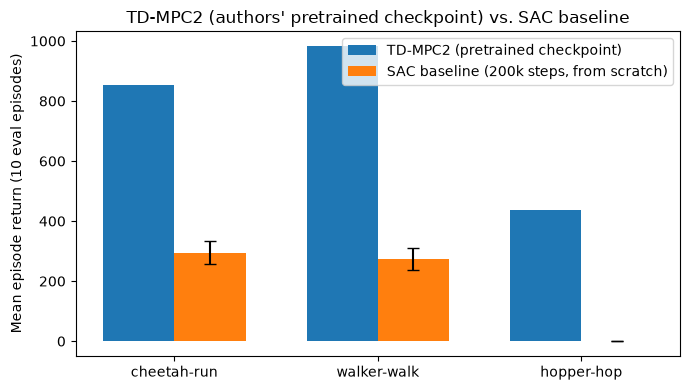

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(len(comparison))
width = 0.35
ax.bar(x - width/2, comparison['tdmpc2_pretrained_return'], width, label='TD-MPC2 (pretrained checkpoint)')
ax.bar(x + width/2, comparison['sac_mean_return'], width, label='SAC baseline (200k steps, from scratch)',
       yerr=comparison['sac_std_return'], capsize=4)
ax.set_xticks(x)
ax.set_xticklabels(comparison['task'])
ax.set_ylabel('Mean episode return (10 eval episodes)')
ax.set_title("TD-MPC2 (authors' pretrained checkpoint) vs. SAC baseline")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'baseline_comparison.png'), dpi=150)
plt.show()

### Discussion — what this comparison does and doesn't establish

Headline numbers: the SAC baseline, trained from scratch for 200,000 steps, reaches roughly 28-35% of the
pretrained TD-MPC2 checkpoint's return on `cheetah-run` and `walker-walk`, and basically fails to learn
`hopper-hop` (mean return close to 0 — the training-time reward collapsed toward zero and stayed there,
consistent with the policy settling into a near-static solution rather than exploring a sparse,
high-exploration-cost task).

This doesn't prove TD-MPC2 is more sample-efficient than SAC in any controlled sense, and I want to
correct that claim here rather than let it stand. The comparison above has unequal training budgets: the
TD-MPC2 number comes from a checkpoint trained to convergence on the authors' own training budget
(undocumented exact figure for these checkpoints, but large — millions of steps per Table 6 of the
paper), while SAC only got 200,000 steps from random initialisation. A fully-trained model beating a
barely-trained one is expected regardless of which algorithm is actually better, so unequal budgets alone
are enough to produce this gap. This plot can't be read as "TD-MPC2 beats SAC in a fair fight."

A genuinely step-matched data point does exist, though, from the Phase 3 bonus sweep (Section 5.2):
training TD-MPC2 itself from scratch for 200,000 steps on `cheetah-run` (Run 3) reached a return of
896.4, compared to SAC's 294.8 at the exact same 200,000-step budget, on the same task. This one
comparison is step-matched, and TD-MPC2 wins it clearly. But it's a single task, single seed comparison —
it doesn't generalise to `walker-walk`/`hopper-hop`, or to a different random seed, without more
evidence. I'd present this in a viva as one genuinely fair data point in TD-MPC2's favour, not as a
settled, general claim.

Why multiple evaluation episodes don't replace multiple independent training seeds: the "10 episodes"
behind every return/std-dev number in this notebook measures variation at evaluation time, under one
already-trained (or, for TD-MPC2, one already-released) model. It says nothing about how much a different
training run — a different random seed, different initial weights, different replay-buffer randomness —
would change the outcome. The SAC standard deviations here (e.g. ±37.81 for `cheetah-run`) describe
spread across 10 evaluation episodes of one trained policy, not spread across independent training runs.
A genuinely seed-robust claim would need repeating the whole training process with several different
seeds and reporting variation across those, which this project, like the paper's own headline figures
(audited in Phase 1 as using only 3 seeds), doesn't fully do.

On `hopper-hop`'s near-zero SAC score: this is a real, measured observation (training reward curve
flatlining near zero, entropy coefficient collapsing toward about 2.6e-5, consistent with a degenerate
near-static policy). A plausible explanation is that `hopper-hop`'s sparse, high-exploration-cost reward
structure is particularly hard for a model-free method to discover within 200k steps without a world
model to plan with — but that's a hypothesis, not a proven cause. I didn't run the controlled experiments
(varying exploration bonuses, comparing against other model-free baselines) that would be needed to
actually confirm it.

On whether the checkpoints were "trained to convergence": I'm not asserting that. The authors' own
training-step figures per task aren't fully documented for these exact released single-task checkpoints.
What I can say with confidence is only that each checkpoint was trained on a substantially larger budget
than SAC's 200k steps here (consistent with Table 6 of the paper, which reports multi-million-step
budgets for DMControl tasks), not the literal number of steps used for this specific file.

## 9. Limitations

- Unequal training budgets between TD-MPC2 (pretrained, authors' full budget) and SAC (200,000 steps
  from scratch) — the single most important caveat, see Section 8.
- Pretrained-artefact evaluation, not training reproduction, for the TD-MPC2 side of the main comparison
  — Section 6 verifies the released checkpoint works, it doesn't reproduce how it was trained.
- Single training seed (`seed=1`) for every new run in this project (SAC and the bonus sweep) — no
  measurement of run-to-run variance from a different seed exists here.
- Limited task coverage: 3 of the paper's 104 tasks for the main comparison; the bonus sweep covers only
  1 of those 3 (`cheetah-run`).
- Compute constraints: a single 4GB-VRAM laptop GPU, which is the direct reason the step budgets, task
  count, and seed count above are all smaller than the paper's own.
- Missing evidence, stated plainly rather than filled in: no saved SAC model file; no per-episode scores
  for either SAC or the pretrained TD-MPC2 evaluation (only aggregate mean/std survive in both cases); no
  raw SAC training log (the bonus TD-MPC2 sweep does have real per-episode training logs, Section 5.2,
  but that's a different, non-required set of runs).
- The observation-noise and model-size/training-steps findings are themselves limited: single-seed, and
  for the noise test, an absolute rather than scale-normalised perturbation — see
  `phase2_results/stress_test_b_noise.md` for the full discussion. Not required by Phase 2, included only
  as forward-looking Phase 3 context.

## 10. Reproducibility and submission package

A small, self-contained submission folder, `phase2_submission/`, sits alongside this notebook. It has
only what's needed to inspect and re-run this project's own work, not the official repository, the
downloaded checkpoints, or the Python virtual environment (all large, externally-available dependencies,
listed below instead of copied):

```
phase2_submission/
├── Phase2_TD_MPC2_Dushara_052_baseline.ipynb   (copy of this notebook)
├── README.md                                    (setup + how to run each part)
├── requirements.txt                             (verified package versions this project depends on)
├── sac_baseline.py                              (the SAC training/eval script)
├── stress_test_noise.py                         (Phase 3 bonus noise-robustness script)
├── tier1_pretrained_results.csv
├── sac_baseline_results.csv
├── stress_test_noise_results.csv
└── training_evidence/
    ├── sweep_eval_results.csv                   (all 5 bonus sweep runs' step-0/final eval returns)
    ├── sample_training_log_excerpt.txt           (real excerpt of one sweep run's training log)
    ├── overrides_size5_steps50k.yaml             (exact Hydra command used for that run)
    └── overrides_tier1_cheetah_run_eval.yaml     (exact Hydra command used for the Tier-1 cheetah eval)
```

Getting the larger external dependencies (not included in the submission folder):
- Official repository: `git clone https://github.com/nicklashansen/tdmpc2.git`, then
  `git checkout e9f59321933cbc8e11a002b842adc7d4ffae8ff1` (the exact revision used here).
- Pretrained checkpoints: download `cheetah-run-1.pt`, `walker-walk-1.pt`, `hopper-hop-1.pt` from
  `huggingface.co/nicklashansen/tdmpc2/tree/main/dmcontrol` into `tdmpc2/checkpoints/`.
- Python environment: create a fresh virtual environment and install the exact versions in
  `requirements.txt`. Don't `pip install` anything else into the same environment afterwards without
  re-checking `numpy`'s version (see Section 3.1 for why).

How to use what's here:
- View saved outputs: open this notebook as-is, every result cell already has its real output embedded,
  nothing needs to be re-run to see the tables/chart.
- Regenerate the table/chart only: re-run this notebook top-to-bottom with both `RUN_LIVE` and
  `RUN_LIVE_SAC` left at `False` (the default) — this just re-reads the saved CSVs and re-draws the
  chart, no GPU, checkpoints, or long wait required.
- Re-run the Tier 1 (TD-MPC2) evaluation genuinely: set `RUN_LIVE=True`; needs the official repo, the 3
  downloaded checkpoints, and a CUDA GPU; takes roughly 1-2 minutes per task.
- Retrain SAC genuinely: set `RUN_LIVE_SAC=True`; needs no GPU (CPU works, just slower) but takes roughly
  20 minutes per task (60 minutes for all 3), and trains 3 separate models that aren't saved anywhere by
  this code.
- Re-run the Phase 3 bonus sweep: not reproduced inside this notebook at all — see the original shell
  driver script referenced in `training_evidence/overrides_size5_steps50k.yaml`'s sibling commands if
  needed. Budget roughly 1-3 hours per run depending on step count, unattended, on a CUDA GPU.

This notebook isn't standalone — it depends on the official `tdmpc2` repository being present at
`tdmpc2/tdmpc2/` relative to wherever it's opened from, and (for `RUN_LIVE=True`) the checkpoints under
`tdmpc2/checkpoints/`. The default (`RUN_LIVE=False`, `RUN_LIVE_SAC=False`) path only needs the small CSV
files bundled in `phase2_submission/`.

## 11. Conclusion

### What was completed

- Evaluated the authors' released pretrained TD-MPC2 checkpoints on 3 tasks using their own unmodified
  evaluation code and protocol.
- Trained a SAC baseline from scratch on the same 3 tasks, using a hand-written environment wrapper that
  matches TD-MPC2's own environment settings exactly.
- Produced a direct comparison table and chart, with the fairness caveats stated explicitly rather than
  implied away.
- (Not required, kept as bonus evidence) Measured observation-noise robustness and ran a
  training-steps/model-size sweep that trained TD-MPC2 itself from scratch five times on one task.

### Main findings

- The released TD-MPC2 checkpoints reproduce strong, plausible locomotion performance on this machine.
- SAC, given only 200,000 steps from scratch, reaches a fraction of that performance on two tasks and
  basically fails on the third (`hopper-hop`) — a real, legitimate property of model-free RL at this
  budget, not a broken baseline.
- A genuinely step-matched comparison (Section 5.2/8) shows TD-MPC2 trained for the same 200,000 steps
  still clearly outperforms SAC on `cheetah-run` — the one data point in this project where the
  comparison is actually fair, though limited to one task and one seed.

### Main limitations

Unequal training budgets in the headline comparison, single seed throughout, 3-of-104 tasks,
pretrained-artefact evaluation rather than training reproduction for the main TD-MPC2 numbers, and a few
explicit evidence gaps (no saved SAC model, no per-episode scores) — see Section 9 for the full list.

## 12. File map

| Item | Verified location |
|---|---|
| Main notebook (this file) | `Phase2_TD_MPC2_Dushara_052_baseline.ipynb` (project root) |
| Original notebook, pre-revision backup | `Phase2_TD_MPC2_Dushara_052_baseline_ORIGINAL_BACKUP.ipynb` (project root) |
| SAC training/eval script | `phase2_results/sac_baseline.py` |
| Noise stress-test script (bonus) | `phase2_results/stress_test_noise.py` |
| Sweep driver script (bonus) | referenced via its recorded Hydra overrides in `phase2_submission/training_evidence/`; the original shell script lived under `/tmp/` during the session and is not preserved long-term — this is stated here rather than silently omitted |
| TD-MPC2 training logs (bonus sweep, real) | `tdmpc2/tdmpc2/outputs/<date>/<time>/` (Hydra run dirs) for config, and genuine per-episode progress captured separately per run (excerpt in `phase2_submission/training_evidence/sample_training_log_excerpt.txt`) |
| Saved TD-MPC2 checkpoints (sweep, real) | `tdmpc2/tdmpc2/logs/cheetah-run/1/<exp_name>/models/final.pt`, one per of the 5 sweep runs |
| Saved SAC models | **None exist** — `sac_baseline.py` never calls `model.save()` (Section 5.1) |
| TD-MPC2 pretrained checkpoints (authors') | `tdmpc2/checkpoints/{cheetah-run,walker-walk,hopper-hop}-1.pt` |
| Evaluation results (CSV) | `phase2_results/tier1_pretrained_results.csv`, `phase2_results/sac_baseline_results.csv`, `phase2_results/stress_test_noise_results.csv` |
| Comparison chart | `phase2_results/baseline_comparison.png` |
| Environment setup instructions | `TDMPC2_SETUP_GUIDE.md` (project root) |
| Phase 2 progress log | `PHASE2_OVERVIEW.md` (project root) |
| Full learning/viva guide (Phases 1 & 2) | `PHASE1_PHASE2_COMPLETE_LEARNING_AND_VIVA_GUIDE.md` (project root) |
| Official coursework brief | `cw_descriptor_bscai_ds.pdf` (project root) |
| Submission package | `phase2_submission/` (project root) — see Section 10 |